# Notebook 03 — Baseline Model Benchmarking

**Input:** `data/processed/data_modelisation.xlsx`  
**Leads to:** `04_energy_star_analysis.ipynb`

This notebook establishes **baseline performance** for predicting building energy
consumption using all 15 structural features (ENERGY STAR Score excluded — it is
unavailable for 35% of buildings and cannot be used in a city-wide deployment).

We compare 7 model families using identical train/test splits and 3-fold cross-validation
to identify which model family is most promising before tuning.

---

**Contents**
1. Modelling strategy
2. Helper functions
3. Experiment B — baseline with all structural features


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.model_selection import (
    train_test_split, cross_validate, KFold, RandomizedSearchCV
)
from sklearn.metrics import (
    r2_score, mean_squared_error, mean_absolute_percentage_error, make_scorer
)
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from catboost import CatBoostRegressor

In [2]:
data_raw = pd.read_excel(r'../data/processed/data_modelisation.xlsx')
data_raw = data_raw.drop(columns=["hasEnergyStarScore", "ENERGYSTARScore"])
print(f"Loaded {len(data_raw)} rows, {len(data_raw.columns)} columns")
data_raw.head()

Loaded 1596 rows, 17 columns


,BuildingType,ZipCode,NumberofFloors,PropertyGFAParking,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,SiteEnergyUseWN(kBtu),TotalGHGEmissions,Age,Ratio_LargestPropertyShare,Ratio_ElectricityShare,EnergyMix,isMixedProperty
0,NonResidential,98101,12,0,hotel,88434,NaN,0,NaN,0,7456910,250,99,1.000000,0.529177,SEN,0
1,NonResidential,98101,11,15064,hotel,83880,parking,15064,restaurant,4622,8664479,296,30,0.947775,0.374270,EN,1
2,NonResidential,98101,10,0,hotel,61320,NaN,0,NaN,0,6946801,286,100,1.000000,0.398590,SEN,0
3,NonResidential,98121,18,62000,hotel,123445,parking,68009,NaN,0,14656503,505,46,0.850914,0.366295,EN,0
4,Nonresidential COS,98101,2,37198,police station,88830,NaN,0,NaN,0,12581712,302,27,0.850914,0.585885,EN,0


## 1. Modelling Strategy

### Dual-target regression
We predict **two targets simultaneously** but independently:
- `SiteEnergyUseWN(kBtu)` — site energy consumption (weather-normalised)
- `TotalGHGEmissions` — greenhouse gas emissions

Each target gets its own pipeline. This avoids the complexity of multi-output
regression while keeping the evaluation framework symmetric.

### Evaluation metrics
- **R²** — proportion of variance explained (1 = perfect, 0 = no better than mean)
- **RMSE** — root mean squared error (same units as the target)
- **MAPE** — mean absolute percentage error (scale-independent; useful for comparing
  across the two very differently-scaled targets)

### 7 model families compared
| Model | Why included |
|---|---|
| `DummyRegressor` | Sanity check — predicts the mean; any real model must beat this |
| `LinearRegression` | Linear baseline; fast and interpretable |
| `Ridge` | Linear + L2 regularisation; handles multicollinearity |
| `Lasso` | Linear + L1 regularisation; performs implicit feature selection |
| `RandomForest` | Ensemble of trees; captures non-linear interactions |
| `GradientBoosting` | Sequential ensemble; often strong on tabular data |
| `CatBoost` | Gradient boosting with native categorical support |

### Preprocessing pipeline
All models receive the same preprocessing:
- Categorical columns → **OneHotEncoder** (`handle_unknown='ignore'`)
- Numeric columns → **StandardScaler** (needed for linear models; harmless for trees)


In [3]:
ENERGY_COL = "SiteEnergyUseWN(kBtu)"
EMISSIONS_COL = "TotalGHGEmissions"

NOISE_COLS = [
    "ZipCode", "PropertyGFAParking", "ThirdLargestPropertyUseType",
    "EnergyMix", "SecondLargestPropertyUseType", "BuildingType", "isMixedProperty",
]

MODELS = {
    "Dummy": DummyRegressor(strategy="mean"),
    "LinearRegression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.001, max_iter=50000),
    "RandomForest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    "GradientBoosting": GradientBoostingRegressor(random_state=42),
    "CatBoost": CatBoostRegressor(verbose=0, random_state=42, iterations=200),
}

RF_PARAM_GRID = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [10, 15, 20, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2", None, 0.5],
    "model__bootstrap": [True, False],
}

## 2. Helper Functions

We define reusable functions used across this notebook and the final model notebook:

- `build_preprocessor(X)` — dynamically builds a `ColumnTransformer` from the
  column dtypes of X
- `prepare_experiment(data, ...)` — performs train/test split and returns a
  structured experiment dict used by the evaluation functions
- `evaluate_models(models, s)` — trains each model and reports test-set metrics
- `cross_validate_models(models, s)` — 3-fold CV on the training set
- `tune_random_forest(...)` — `RandomizedSearchCV` with 30 iterations
- `plot_feature_importance(...)` — plots top-N feature importances from a fitted pipeline


In [4]:
def build_preprocessor(X):
    """Build a ColumnTransformer from X's dtypes."""
    cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()
    num_cols = X.select_dtypes(exclude=["object", "category"]).columns.tolist()
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ("num", StandardScaler(), num_cols),
    ])


def prepare_experiment(data, use_energy_as_ghg_predictor=False, log_targets=False):
    """Prepare train/test splits and preprocessors for an experiment."""
    data = data.copy()
    for col in data.select_dtypes(include=["object", "category"]).columns:
        data[col] = data[col].astype(str)

    X = data.drop(columns=[ENERGY_COL, EMISSIONS_COL])
    y_e = data[ENERGY_COL].copy()
    y_g = data[EMISSIONS_COL].copy()

    if log_targets:
        y_e = np.log1p(y_e)
        y_g = np.log1p(y_g)

    prep_e = build_preprocessor(X)

    if use_energy_as_ghg_predictor:
        X_g = data.drop(columns=[EMISSIONS_COL])
        for col in X_g.select_dtypes(include=["object", "category"]).columns:
            X_g[col] = X_g[col].astype(str)
        prep_g = build_preprocessor(X_g)
    else:
        X_g = X.copy()
        prep_g = build_preprocessor(X_g)

    train_idx, test_idx = train_test_split(data.index, test_size=0.2, random_state=42)
    return {
        "X_tr_e": X.loc[train_idx], "X_te_e": X.loc[test_idx],
        "y_tr_e": y_e.loc[train_idx], "y_te_e": y_e.loc[test_idx],
        "X_tr_g": X_g.loc[train_idx], "X_te_g": X_g.loc[test_idx],
        "y_tr_g": y_g.loc[train_idx], "y_te_g": y_g.loc[test_idx],
        "prep_e": prep_e, "prep_g": prep_g,
        "log_targets": log_targets,
    }

In [5]:
def evaluate_models(models, s):
    """Train/test evaluation for all models. Metrics always in original scale."""
    results = []
    for name, model in models.items():
        pipe_e = Pipeline([("preprocessor", clone(s["prep_e"])), ("model", clone(model))])
        pipe_e.fit(s["X_tr_e"], s["y_tr_e"])
        pred_e = pipe_e.predict(s["X_te_e"])

        pipe_g = Pipeline([("preprocessor", clone(s["prep_g"])), ("model", clone(model))])
        pipe_g.fit(s["X_tr_g"], s["y_tr_g"])
        pred_g = pipe_g.predict(s["X_te_g"])

        y_te_e, y_te_g = s["y_te_e"], s["y_te_g"]
        if s["log_targets"]:
            y_te_e = np.expm1(y_te_e)
            pred_e = np.expm1(pred_e)
            y_te_g = np.expm1(y_te_g)
            pred_g = np.expm1(pred_g)

        results.append({
            "Model": name,
            "R2_Energy": r2_score(y_te_e, pred_e),
            "RMSE_Energy": np.sqrt(mean_squared_error(y_te_e, pred_e)),
            "MAPE_Energy": mean_absolute_percentage_error(y_te_e, pred_e),
            "R2_GHG": r2_score(y_te_g, pred_g),
            "RMSE_GHG": np.sqrt(mean_squared_error(y_te_g, pred_g)),
            "MAPE_GHG": mean_absolute_percentage_error(y_te_g, pred_g),
        })
    return pd.DataFrame(results).sort_values("R2_Energy", ascending=False)


def cross_validate_models(models, s):
    """3-fold CV on training data. Metrics in target space (log for Exp D)."""
    cv = KFold(n_splits=3, shuffle=True, random_state=42)
    rmse_scorer = make_scorer(
        lambda y, p: np.sqrt(mean_squared_error(y, p)), greater_is_better=False
    )
    scoring = {"r2": "r2", "neg_rmse": rmse_scorer}

    cv_results = []
    for name, model in models.items():
        pipe_e = Pipeline([("preprocessor", clone(s["prep_e"])), ("model", clone(model))])
        sc_e = cross_validate(pipe_e, s["X_tr_e"], s["y_tr_e"], cv=cv, scoring=scoring)

        pipe_g = Pipeline([("preprocessor", clone(s["prep_g"])), ("model", clone(model))])
        sc_g = cross_validate(pipe_g, s["X_tr_g"], s["y_tr_g"], cv=cv, scoring=scoring)

        cv_results.append({
            "Model": name,
            "R2_Energy_Mean": sc_e["test_r2"].mean(),
            "R2_Energy_SD": sc_e["test_r2"].std(),
            "RMSE_Energy_Mean": -sc_e["test_neg_rmse"].mean(),
            "R2_GHG_Mean": sc_g["test_r2"].mean(),
            "R2_GHG_SD": sc_g["test_r2"].std(),
            "RMSE_GHG_Mean": -sc_g["test_neg_rmse"].mean(),
        })
    return pd.DataFrame(cv_results).sort_values("R2_Energy_Mean", ascending=False)

In [6]:
def tune_random_forest(preprocessor, X_train, y_train, target_name):
    """RandomizedSearchCV (10 iterations) for RandomForest."""
    pipe = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", RandomForestRegressor(random_state=42))
    ])
    search = RandomizedSearchCV(
        pipe, RF_PARAM_GRID, n_iter=10, cv=3, scoring="r2",
        n_jobs=-1, random_state=42, verbose=1
    )
    print(f"\nTuning RandomForest for {target_name}...")
    search.fit(X_train, y_train)
    print(f"Best CV R2 ({target_name}): {search.best_score_:.4f}")
    for k, v in search.best_params_.items():
        print(f"  {k}: {v}")
    return search

In [7]:
def get_pipeline_feature_names(pipeline, X):
    """Extract feature names from a fitted pipeline with ColumnTransformer."""
    pre = pipeline.named_steps.get("preprocessor", None)
    if pre is None:
        return list(X.columns) if hasattr(X, "columns") else [f"f_{i}" for i in range(X.shape[1])]
    try:
        return list(pre.get_feature_names_out())
    except Exception:
        pass
    if isinstance(pre, ColumnTransformer):
        names = []
        for name, transformer, cols in pre.transformers_:
            if transformer in ("drop",) or (name == "remainder" and transformer == "drop"):
                continue
            if transformer == "passthrough":
                names.extend(list(cols) if hasattr(cols, "__iter__") else [str(cols)])
                continue
            try:
                names.extend(list(transformer.get_feature_names_out(
                    cols if hasattr(cols, "__iter__") else [cols]
                )))
            except Exception:
                if hasattr(cols, "__iter__"):
                    names.extend([f"{name}__{c}" for c in cols])
                else:
                    names.append(f"{name}__{cols}")
        if names:
            return names
    return [f"f_{i}" for i in range(pre.transform(X).shape[1])]


def plot_feature_importance(pipeline, X, y, title, top_n=20, color="#4C78A8"):
    """Fit pipeline, extract and plot feature importances."""
    pipeline.fit(X, y)
    model = pipeline.named_steps[list(pipeline.named_steps.keys())[-1]]
    imps = getattr(model, "feature_importances_", None)
    if imps is None:
        print(f"No feature_importances_ for: {title}")
        return None
    names = get_pipeline_feature_names(pipeline, X)
    df = pd.DataFrame({"Feature": names, "Importance": imps})
    df = df.sort_values("Importance", ascending=False).head(top_n)
    plt.figure(figsize=(9, 6))
    plt.barh(df["Feature"].iloc[::-1], df["Importance"].iloc[::-1], color=color)
    plt.title(title, fontsize=12, fontweight="bold")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()
    return df

## 3. Experiment B — Baseline: All Structural Features

We use all 15 available structural features (after removing `ENERGYSTARScore`
and `hasEnergyStarScore` which will be analysed separately in notebook 04).

Both targets are predicted independently using the same feature set.
The train/test split is 80/20 with `random_state=42` for reproducibility.


In [8]:
data_b = data_raw.copy()
s_b = prepare_experiment(data_b)
print(f"Train: {s_b['X_tr_e'].shape}, Test: {s_b['X_te_e'].shape}")
print(f"Features: {list(s_b['X_tr_e'].columns)}")

Train: (1276, 15), Test: (320, 15)
Features: ['BuildingType', 'ZipCode', 'NumberofFloors', 'PropertyGFAParking', 'LargestPropertyUseType', 'LargestPropertyUseTypeGFA', 'SecondLargestPropertyUseType', 'SecondLargestPropertyUseTypeGFA', 'ThirdLargestPropertyUseType', 'ThirdLargestPropertyUseTypeGFA', 'Age', 'Ratio_LargestPropertyShare', 'Ratio_ElectricityShare', 'EnergyMix', 'isMixedProperty']


### 3.1 Train / Test Evaluation

The table below shows metrics on the held-out test set (20% of the data).
A high R² on the test set — not the training set — indicates genuine generalisation.

**What to look for:**
- Any model with R² < 0 performs **worse** than predicting the mean (broken model)
- Linear models often plateau below tree-based models on tabular data with interactions
- Compare Energy and GHG columns — some models may specialise differently


In [9]:
results_b = evaluate_models(MODELS, s_b)
print("Test Set Results (Experiment B):\n")
display(results_b)

C:\Users\shahu\Documents\OneDrive\OPEN CLASSROOMS\PROJET 3\Predict Energy Consumption\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.289e+15, tolerance: 9.519e+12
  model = cd_fast.enet_coordinate_descent(


Test Set Results (Experiment B):



,Model,R2_Energy,RMSE_Energy,MAPE_Energy,R2_GHG,RMSE_GHG,MAPE_GHG
6,CatBoost,7.827814e-01,3.687672e+06,8.776722e-01,6.621996e-01,1.025095e+02,1.214861e+00
5,GradientBoosting,7.782237e-01,3.726159e+06,9.692362e-01,6.448185e-01,1.051136e+02,1.595858e+00
4,RandomForest,7.780076e-01,3.727974e+06,8.887888e-01,6.953089e-01,9.735622e+01,9.731567e-01
2,Ridge,6.786262e-01,4.485481e+06,1.288431e+00,3.452726e-01,1.427132e+02,3.569548e+00
3,Lasso,6.307085e-01,4.808266e+06,1.372110e+00,1.942836e-01,1.583160e+02,3.881803e+00
0,Dummy,-2.893857e-04,7.913464e+06,3.758272e+00,-9.040109e-04,1.764534e+02,7.493740e+00
1,LinearRegression,-9.608216e+20,2.452591e+17,1.123761e+10,-5.248250e+20,4.040555e+12,1.073735e+10


### 3.2 Cross-Validation (3-Fold)

Train/test evaluation on a single split can be noisy. 3-fold cross-validation
on the **training data** gives a more stable estimate of generalisation performance.

The standard deviation columns (`R2_Energy_SD`, `R2_GHG_SD`) reveal model stability:
high SD = the model is sensitive to which data it trains on.


In [10]:
cv_b = cross_validate_models(MODELS, s_b)
print("Cross-Validation Results (Experiment B):\n")
display(cv_b)

C:\Users\shahu\Documents\OneDrive\OPEN CLASSROOMS\PROJET 3\Predict Energy Consumption\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.967e+15, tolerance: 6.562e+12
  model = cd_fast.enet_coordinate_descent(


C:\Users\shahu\Documents\OneDrive\OPEN CLASSROOMS\PROJET 3\Predict Energy Consumption\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.194e+15, tolerance: 5.862e+12
  model = cd_fast.enet_coordinate_descent(


C:\Users\shahu\Documents\OneDrive\OPEN CLASSROOMS\PROJET 3\Predict Energy Consumption\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.413e+14, tolerance: 6.611e+12
  model = cd_fast.enet_coordinate_descent(


Cross-Validation Results (Experiment B):



,Model,R2_Energy_Mean,R2_Energy_SD,RMSE_Energy_Mean,R2_GHG_Mean,R2_GHG_SD,RMSE_GHG_Mean
6,CatBoost,6.874220e-01,1.424760e-02,4.823319e+06,6.193911e-01,4.190188e-02,1.242464e+02
5,GradientBoosting,6.642905e-01,2.323684e-02,4.998547e+06,5.665897e-01,1.440478e-02,1.328076e+02
2,Ridge,6.381750e-01,7.522810e-02,5.147069e+06,4.098129e-01,1.178464e-01,1.534759e+02
4,RandomForest,6.363882e-01,2.644289e-02,5.203559e+06,5.581344e-01,2.610452e-02,1.343380e+02
3,Lasso,5.985826e-01,8.721321e-02,5.414069e+06,3.102438e-01,2.131739e-01,1.642793e+02
0,Dummy,-1.746459e-03,1.234234e-03,8.629370e+06,-3.635600e-03,2.852188e-03,2.022973e+02
1,LinearRegression,-4.614836e+20,3.821594e+20,1.607030e+17,-1.348161e+21,1.587762e+21,5.929349e+12


### 3.3 Hyperparameter Tuning — Random Forest

Random Forest consistently performs well on tabular regression tasks. We run
`RandomizedSearchCV` with **30 iterations** over a wide grid covering:
- Number of trees (`n_estimators`)
- Maximum tree depth
- Minimum samples per split and per leaf
- Feature sampling strategy
- Bootstrap on/off

The best parameters are printed below and will be compared against
the tuned models in notebook 05.


In [11]:
search_b_e = tune_random_forest(s_b["prep_e"], s_b["X_tr_e"], s_b["y_tr_e"], "Energy-B")
search_b_g = tune_random_forest(s_b["prep_g"], s_b["X_tr_g"], s_b["y_tr_g"], "GHG-B")


Tuning RandomForest for Energy-B...
Fitting 3 folds for each of 10 candidates, totalling 30 fits


Best CV R2 (Energy-B): 0.6421
  model__n_estimators: 200
  model__min_samples_split: 2
  model__min_samples_leaf: 1
  model__max_features: 0.5
  model__max_depth: 20
  model__bootstrap: True

Tuning RandomForest for GHG-B...
Fitting 3 folds for each of 10 candidates, totalling 30 fits


Best CV R2 (GHG-B): 0.5346
  model__n_estimators: 300
  model__min_samples_split: 2
  model__min_samples_leaf: 1
  model__max_features: 0.5
  model__max_depth: 20
  model__bootstrap: True


### 3.4 Feature Importance

Feature importances from the **tuned Random Forest** show which structural attributes
drive predictions most strongly for each target.

These importances will inform the noise-reduction experiment in
`05_final_model_and_results.ipynb`, where we drop low-importance features
and check whether performance improves.


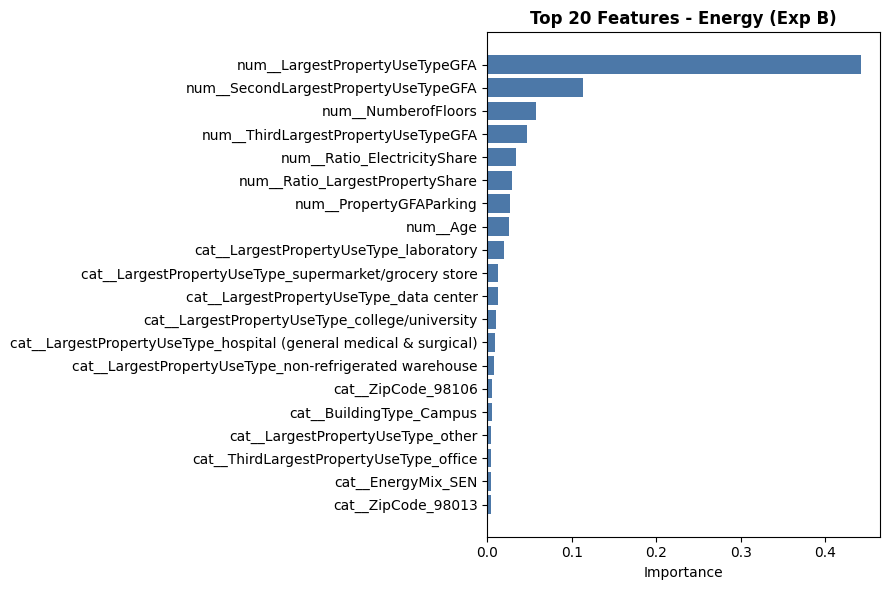

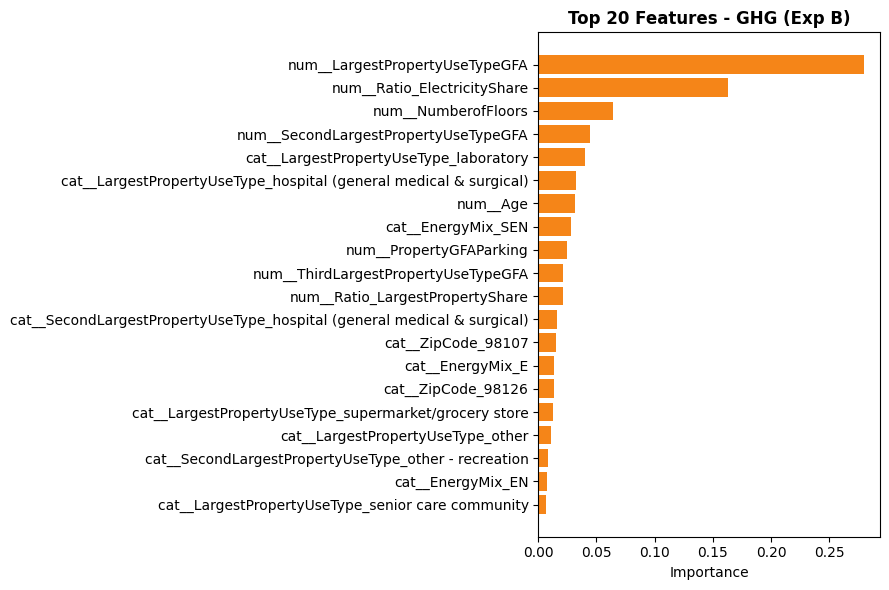

,Feature,Importance
188,num__LargestPropertyUseTypeGFA,0.279780
193,num__Ratio_ElectricityShare,0.163338
186,num__NumberofFloors,0.064250
189,num__SecondLargestPropertyUseTypeGFA,0.044331
63,cat__LargestPropertyUseType_laboratory,0.039755
60,cat__LargestPropertyUseType_hospital (general ...,0.032292
191,num__Age,0.031109
185,cat__EnergyMix_SEN,0.027703
187,num__PropertyGFAParking,0.025019
190,num__ThirdLargestPropertyUseTypeGFA,0.021215


In [12]:
plot_feature_importance(search_b_e.best_estimator_, s_b["X_tr_e"], s_b["y_tr_e"],
                       "Top 20 Features - Energy (Exp B)", color="#4C78A8")
plot_feature_importance(search_b_g.best_estimator_, s_b["X_tr_g"], s_b["y_tr_g"],
                       "Top 20 Features - GHG (Exp B)", color="#F58518")

## Baseline Summary

| Model family | Energy R² (approx.) | GHG R² (approx.) | Verdict |
|---|---|---|---|
| Dummy | ~0 | ~0 | Sanity check only |
| Linear / Ridge / Lasso | Low–Medium | Low–Medium | Cannot capture non-linear interactions |
| **Random Forest** | **High** | **High** | **Best baseline** |
| GradientBoosting | High | High | Competitive with RF |
| CatBoost | High | High | Competitive with RF |

**Next:** `04_energy_star_analysis.ipynb` — explore what happens when we
add `ENERGYSTARScore` as a feature (available for 65% of buildings).
